# Token Brief

A one-protocol tear sheet built from the cached pulls in `data/`, the data-collection helpers in `src/data/data_collection.py`, and the chart functions in `src/visualization`.

**How to use**

1. Set `PROTOCOL` in the input cell below to any name the protocol index knows (index key, display name, DefiLlama slug or Messari slug; case-insensitive).
2. Run all cells. The freshness check repulls only the metrics this notebook displays, and only for the (protocol, metric) pairs that are missing or stale.

**Prerequisites**

- `API_KEYS.env` with `MESSARI_API_KEY` (market cap repulls). DefiLlama needs no key; with `DEFILLAMA_API_KEY` set its pulls run on the Pro host (faster repulls, no free-tier throttling).
- The protocol and its peer category must exist in `config/protocol_index.json`.
- The processed valuation multiples (`data/processed/valuation-multiples/*.json`) should have been built at least once by `example-pull-raw-data.ipynb`. This notebook rebuilds them when the underlying data is repulled.

**Sections**

1. DefiLlama description
2. Single-asset daily metrics (fees, revenue, holders revenue, TVL)
3. Peer cohort fees (cohort = every protocol sharing the target's `category` in the protocol index)
4. Category valuation multiples (chart + statistics table)
5. Implied valuation from category multiples


In [1]:
# Setup
import os
import sys
import time
import datetime

import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display, Markdown

# Load env variables
load_dotenv("API_KEYS.env")
messari_api_key = os.getenv("MESSARI_API_KEY")

# Import data collection functions
sys.path.append('src')
from data import data_collection

# Import visualization functions
from visualization import visualization

# Import utils functions
sys.path.append('utils')
import helper_functions

today = datetime.datetime.today()
date = helper_functions.format_date_with_suffix(today)
run_start = time.time()

# Define outputs filepath
plots_filepath = 'outputs/plots'
tables_filepath = 'outputs/tables'
for _p in (plots_filepath, tables_filepath):
    os.makedirs(_p, exist_ok=True)


In [2]:
# INPUTS -- edit this cell only

PROTOCOL = 'Uniswap'   # index key, display name, DefiLlama slug or Messari slug (case-insensitive)

START_DATE = '2026-01-01'          # start of the daily-metric charts
TRAILING_WINDOW = 7                # trailing average window (days) for daily metrics

SINGLE_ASSET_METRICS = ['dailyFees', 'dailyRevenue', 'dailyHoldersRevenue', 'dailyEarnings', 'tvl']
COHORT_METRIC = 'dailyFees'        # one of dailyFees / dailyRevenue / dailyHoldersRevenue / dailyEarnings / tvl
# dailyEarnings = revenue - incentives (DefiLlama's Earnings); derived from the Pro-only incentives
# pull, so it needs DEFILLAMA_API_KEY and is skipped when the file is absent.

MULTIPLES_METRIC = 'MCAP-to-annualized-fees-multiple-7d'                    # category multiples chart
MULTIPLES_START_DATE = '2026-01-01'
IMPLIED_VALUATION_MULTIPLE = 'FDV-weighted-FDV-to-annualized-fees-multiple-7d'  # implied valuation

# Data freshness
REPULL_STALE = True        # False = report staleness only, never hit the APIs
MAX_STALE_DAYS = 3         # DefiLlama / Messari daily series normally lag 1-2 days
REBUILD_MULTIPLES = False  # True = rebuild data/processed/valuation-multiples even if nothing was repulled


## Resolve the protocol

`data_collection.resolve_protocol` looks the input up in `config/protocol_index.json`. The index key (standard name) is what every file under `data/raw/` is named by, so all later cells use it.

In [3]:
try:
    slug, entry = data_collection.resolve_protocol(PROTOCOL)
except data_collection.ProtocolNotFoundError as e:
    raise SystemExit(e)

name = entry['display_name']
category = entry['category']
pretty_category = category.replace('_', ' ').title()

print(f"{name}  (index key: {slug})")
print(f"  category:        {category}")
print(f"  defillama slug:  {entry.get('defillama_slug')}")
print(f"  messari slug:    {entry.get('messari_slug')}")

# Confirm the DefiLlama slug is the parent protocol (all versions/components), not one component
components = data_collection.parent_components(entry.get('defillama_slug'))
if len(components) > 1:
    print(f"  aggregates {len(components)} DefiLlama sub-protocols: {', '.join(c['name'] for c in components)}")


Uniswap V3  (index key: uniswap)
  category:        dexs
  defillama slug:  uniswap
  messari slug:    uniswap


## Data freshness check

Only the data this notebook actually displays is checked and, if needed, repulled (`data_collection.required_data` derives the set from the inputs above):

| Output | Target needs | Each peer needs |
|---|---|---|
| Description | DefiLlama `tvl` | - |
| Single-asset charts | DefiLlama files for `SINGLE_ASSET_METRICS` (`dailyEarnings` also needs its inputs `revenue` + `incentives`) | - |
| Cohort chart | DefiLlama file for `COHORT_METRIC` | same |
| Category multiples / implied valuation | DefiLlama bottom metric of the multiple + Messari `marketcap` | same |

A file is **fresh** when its last data point is within `MAX_STALE_DAYS` of today. Stale or missing (protocol, metric) pairs are repulled one metric at a time with the existing `defillama` / `messari` pull functions. DefiLlama daily flows (fees / revenue / holders revenue / incentives) drop the in-progress current UTC day at pull time, so the freshest possible point is yesterday. `earnings` is derived (revenue - incentives, DefiLlama's definition; incentives are the USD value of tokens emitted as farming / staking rewards, from the Pro emission endpoint) and is rebuilt whenever it or an input is stale; without `DEFILLAMA_API_KEY` it stays missing and the earnings chart is skipped. If anything in the category was repulled, the processed valuation multiples are rebuilt the same way `example-pull-raw-data.ipynb` does (a local recomputation over every category already in the file, so nothing is dropped; it takes a minute or two).

In [4]:
REQUIRED = data_collection.required_data(SINGLE_ASSET_METRICS, COHORT_METRIC,
                                         [MULTIPLES_METRIC, IMPLIED_VALUATION_MULTIPLE])

checks = data_collection.check_data(slug, category, REQUIRED, max_stale_days=MAX_STALE_DAYS)
display(checks.drop(columns='path'))

stale_raw = checks[(checks.status != 'fresh') & (checks.scope != 'processed')]
processed_stale = (checks[checks.scope == 'processed'].status != 'fresh').any()
repulled = False

if stale_raw.empty:
    print('All required raw data is fresh.')
elif not REPULL_STALE:
    print(f"{len(stale_raw)} stale/missing files; REPULL_STALE=False so continuing with cached data.")
else:
    print(f"Repulling {len(stale_raw)} stale/missing (protocol, metric) pairs...\n")
    pull = data_collection.repull_stale(checks, messari_api_key=messari_api_key, max_stale_days=MAX_STALE_DAYS)
    repulled = pull['repulled']
    if pull['checks'] is not None:
        print('\nAfter repull:')
        display(pull['checks'].drop(columns='path'))

if REBUILD_MULTIPLES or (REPULL_STALE and (repulled or processed_stale)):
    data_collection.rebuild_valuation_multiples(ensure_category=category)

# Flags for the sections below
HAS_TVL = data_collection.has_raw('defillama', 'tvl', slug)
HAS_FEES = data_collection.has_raw('defillama', 'fees', slug)
HAS_REVENUE = data_collection.has_raw('defillama', 'revenue', slug)

cohort_dir = data_collection.API_TO_DIR[COHORT_METRIC]
peers, dropped = data_collection.cohort_assets(category, cohort_dir)
if dropped:
    print(f"Dropped from cohort (no {cohort_dir} file): {', '.join(dropped)}")

HAS_MULTIPLES, HAS_WEIGHTED = data_collection.multiples_availability(slug, category)

if not HAS_TVL and not (HAS_FEES or HAS_REVENUE):
    raise SystemExit(f"No DefiLlama tvl/fees/revenue data for {name}. Run the 'pull_metric_data_by_asset' cell in example-pull-raw-data.ipynb for '{slug}'.")

print(f"\nSections: description={HAS_TVL}  single-asset={HAS_FEES or HAS_REVENUE or HAS_TVL}  cohort={len(peers) >= 2}  multiples={HAS_MULTIPLES}  implied valuation={HAS_WEIGHTED and HAS_MULTIPLES}")


,scope,protocol,source,metric,last_date,status
0,target,uniswap,defillama,fees,2026-09-22,fresh
1,target,uniswap,defillama,holders-revenue,2026-09-22,fresh
2,target,uniswap,defillama,revenue,2026-09-22,fresh
3,target,uniswap,defillama,tvl,2026-09-23,fresh
4,target,uniswap,messari,marketcap,2026-09-23,fresh
5,peer,aerodrome,defillama,fees,2026-09-22,fresh
6,peer,aerodrome,messari,marketcap,2026-09-23,fresh
7,peer,orca,defillama,fees,2026-09-22,fresh
8,peer,orca,messari,marketcap,2026-09-23,fresh
9,peer,chainflip,defillama,fees,2026-09-22,fresh


Repulling 22 stale/missing (protocol, metric) pairs...

DefiLlama fees: dragon-swap, hydrex, ramses-exchange-hl


DefiLlama metric data: 100%|██████████| 3/3 [00:03<00:00,  1.29s/pull]

Failed pulls: [('fees', 'dragon-swap')]
Note: defillama has no fees data for ramses-exchange-hl after 2026-04-17 (the partial current day is dropped at pull time).

After repull:


,scope,protocol,source,metric,last_date,status
12,peer,project-x,messari,marketcap,None,missing
14,peer,thorchain-dex,messari,marketcap,None,missing
16,peer,up,messari,marketcap,None,missing
18,peer,pharaoh-exchange,messari,marketcap,None,missing
20,peer,ring-protocol,messari,marketcap,None,missing
21,peer,dragon-swap,defillama,fees,None,missing
22,peer,dragon-swap,messari,marketcap,None,missing
24,peer,pulsex,messari,marketcap,None,missing
26,peer,velodrome,messari,marketcap,None,missing
28,peer,nest,messari,marketcap,None,missing


Rebuilding valuation multiples for categories: borrow_lend_protocols, dexs, liquid_staking, perps_dexs, physical_tcg, smart_contract_chains

Determining global date range...
Global date range: 2015-08-07 to 2026-09-23 (4066 days)

Processing category: borrow_lend_protocols
  Processing asset: aave
    Replaced 7 outlier multiple values for aave (>100x from trailing 90d median) across 3 multiples
  Processing asset: morpho
    Replaced 22 outlier multiple values for morpho (>100x from trailing 90d median) across 4 multiples
  Processing asset: compound-finance
  Processing asset: kamino
  Processing asset: maple-finance
    Replaced 111 outlier multiple values for maple-finance (>100x from trailing 90d median) across 6 multiples
  Processing asset: euler
    Replaced 336 outlier multiple values for euler (>100x from trailing 90d median) across 16 multiples
  Processing asset: spark
    Replaced 268 outlier multiple values for spark (>100x from trailing 90d median) across 6 multiples

Pr

KeyboardInterrupt: 

## 1. Description (DefiLlama)

In [ ]:
def usd(x):
    """Format a dollar amount with the repo's large-number formatter ($1.2b, $340m, ...)."""
    if x is None or pd.isna(x):
        return 'n/a'
    return helper_functions.format_large_numbers(abs(x))(x)


if HAS_TVL:
    meta = data_collection.load_defillama_metadata(slug)

    latest_tvl = meta['tvl'][-1]['totalLiquidityUSD'] if meta.get('tvl') else None
    # currentChainTvls mixes chains with DefiLlama's non-chain buckets (borrowed, staking, pool2, ...)
    NON_CHAIN_KEYS = {'borrowed', 'staking', 'pool2', 'vesting', 'treasury', 'offers', 'doublecounted', 'liquidstaking'}
    chain_tvls = {k: v for k, v in (meta.get('currentChainTvls') or {}).items()
                  if '-' not in k and k.lower() not in NON_CHAIN_KEYS}
    top_chains = sorted(chain_tvls, key=chain_tvls.get, reverse=True)[:8]

    lines = [
        f"### {meta.get('name', name)} ({meta.get('symbol') or '-'})",
        '',
        meta.get('description') or '_No description provided by DefiLlama._',
        '',
    ]
    if meta.get('category'):
        lines.append(f"- **DefiLlama category:** {meta['category']}")
    lines += [
        f"- **Website:** {meta.get('url', '-')}",
        f"- **Twitter:** @{meta.get('twitter')}" if meta.get('twitter') else '- **Twitter:** -',
        f"- **Chains ({len(chain_tvls)}):** {', '.join(top_chains)}{'...' if len(chain_tvls) > 8 else ''}",
        f"- **Latest TVL:** {usd(latest_tvl)}",
        f"- **Market cap (DefiLlama):** {usd(float(meta['mcap'])) if meta.get('mcap') else 'n/a'}",
        f"- **Raises tracked:** {len(meta.get('raises') or [])}  |  **Hacks tracked:** {len(meta.get('hacks') or [])}",
        '',
        f"_Source: data/raw/defillama/tvl/{slug}.json_",
    ]
    display(Markdown('\n'.join(lines)))
else:
    print(f'No DefiLlama tvl file for {name}; description unavailable.')


### Aave (AAVE)

Aave is an Open Source and Non-Custodial protocol to earn interest on deposits and borrow assets

- **Website:** https://aave.com
- **Twitter:** @aave
- **Chains (23):** Ethereum, Base, Arbitrum, Plasma, Monad, Avalanche, BSC, Polygon...
- **Latest TVL:** $19b
- **Market cap (DefiLlama):** $2.1b
- **Raises tracked:** 4  |  **Hacks tracked:** 1

_Source: data/raw/defillama/tvl/aave.json_

## 2. Single-asset daily metrics

Trailing-average daily fees / revenue / holders revenue (annualized) and TVL, then all of them on one combined chart.

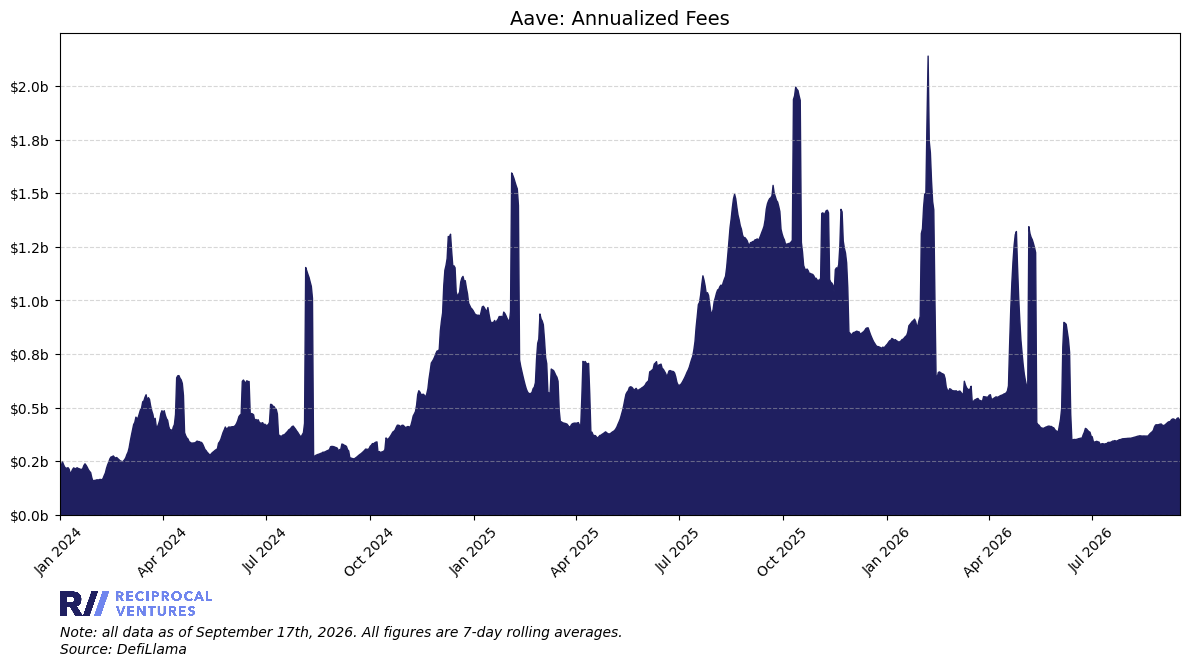

           date       fees       fees-7d
2109 2026-09-13  428427145  4.429620e+08
2110 2026-09-14  500605165  4.517926e+08
2111 2026-09-15  459459080  4.540596e+08
2112 2026-09-16  422950320  4.458139e+08
2113 2026-09-17  427985130  4.429588e+08


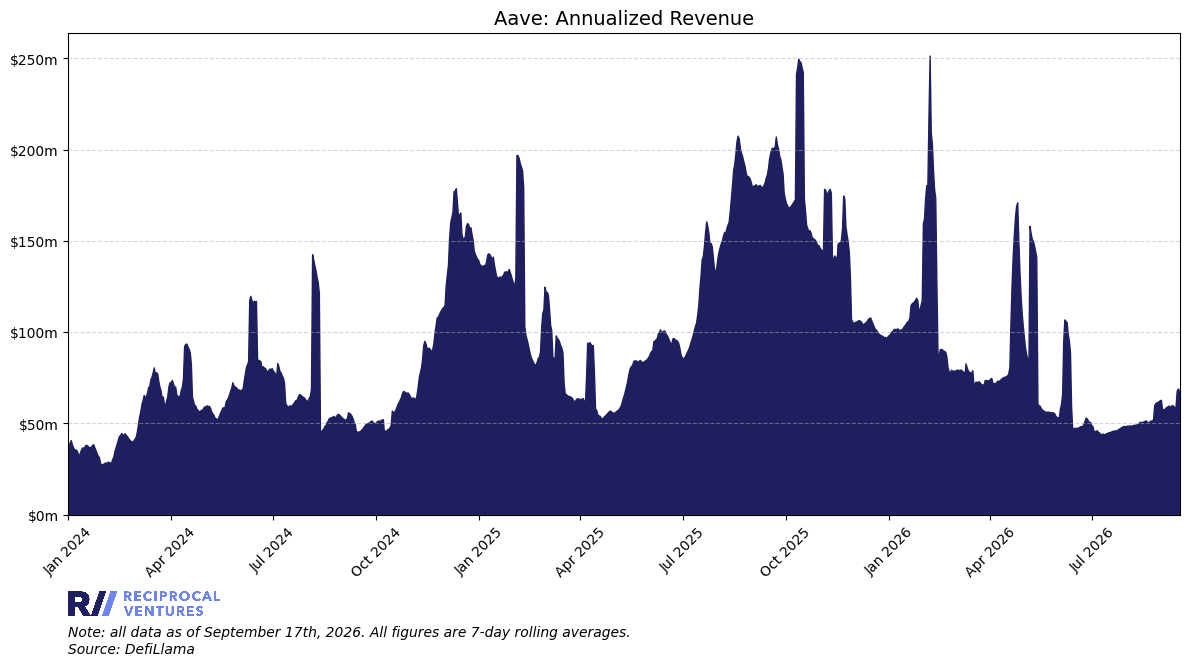

           date    revenue    revenue-7d
2109 2026-09-13   58279915  5.882627e+07
2110 2026-09-14  122143965  6.776397e+07
2111 2026-09-15   70140955  6.917308e+07
2112 2026-09-16   55730755  6.799694e+07
2113 2026-09-17   55686590  6.763236e+07


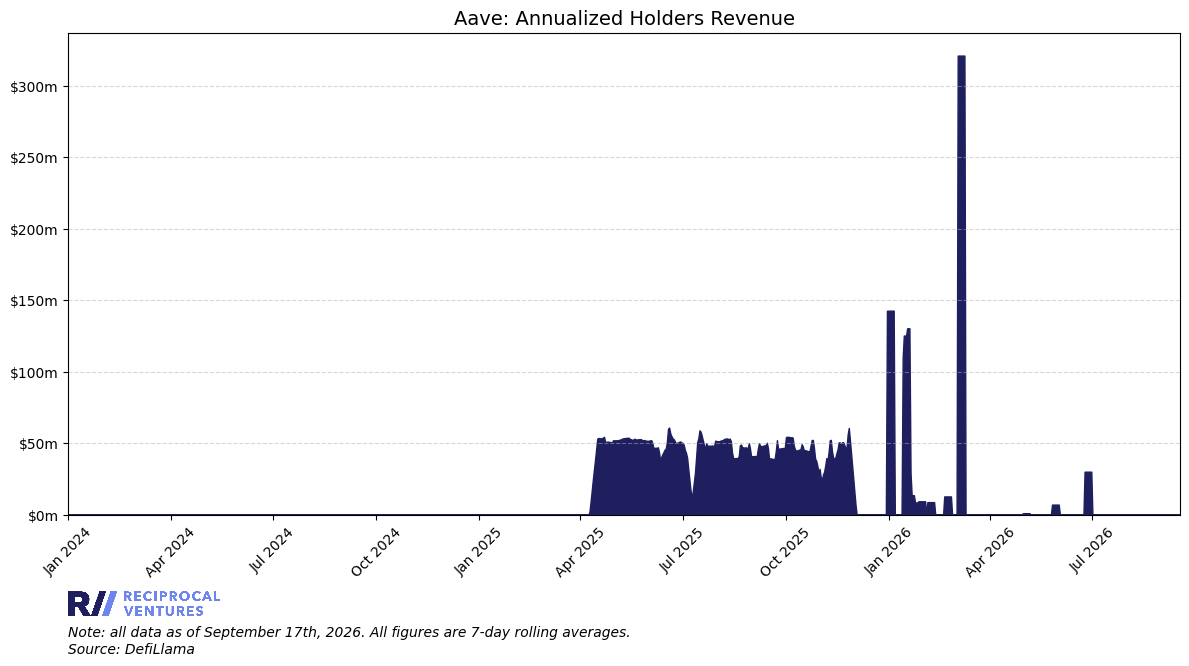

           date  holders-revenue  holders-revenue-7d
2109 2026-09-13                0                 0.0
2110 2026-09-14                0                 0.0
2111 2026-09-15                0                 0.0
2112 2026-09-16                0                 0.0
2113 2026-09-17                0                 0.0


did not annualize TVL


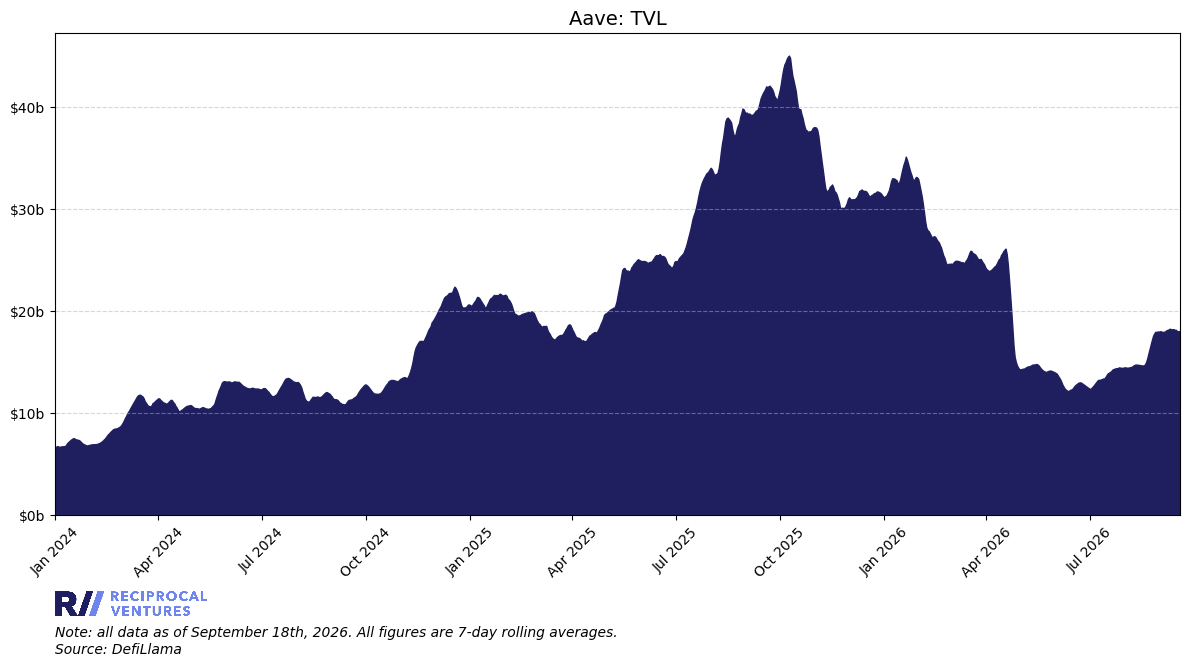

                    date          tvl        tvl-7d
2309 2026-09-15 00:00:00  18263518777  1.814218e+10
2310 2026-09-16 00:00:00  17533103235  1.802972e+10
2311 2026-09-17 00:00:00  17757105298  1.800002e+10
2312 2026-09-18 00:00:00  17720474449  1.799103e+10
2313 2026-09-18 18:08:47  18788761662  1.806457e+10


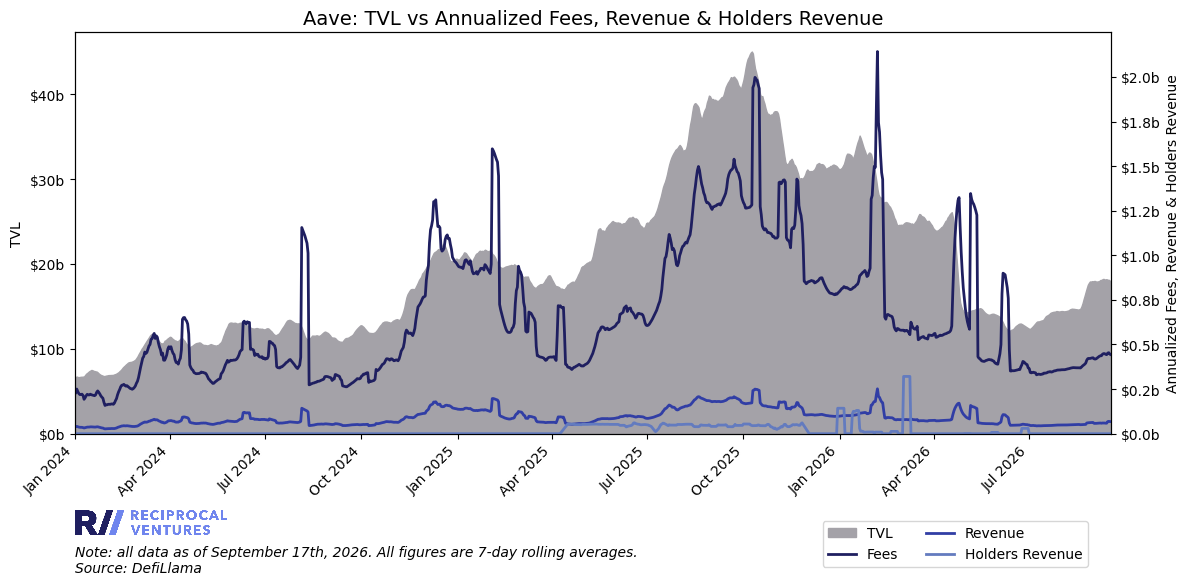

           date       fees-7d    revenue-7d  holders-revenue-7d        tvl-7d
2109 2026-09-13  4.429620e+08  5.882627e+07                 0.0  1.820129e+10
2110 2026-09-14  4.517926e+08  6.776397e+07                 0.0  1.814324e+10
2111 2026-09-15  4.540596e+08  6.917308e+07                 0.0  1.814218e+10
2112 2026-09-16  4.458139e+08  6.799694e+07                 0.0  1.802972e+10
2113 2026-09-17  4.429588e+08  6.763236e+07                 0.0  1.800002e+10


In [ ]:
metrics = [m for m in SINGLE_ASSET_METRICS if data_collection.has_raw('defillama', data_collection.API_TO_DIR[m], slug)]
missing_metrics = [m for m in SINGLE_ASSET_METRICS if m not in metrics]
if missing_metrics:
    print(f"Skipping {', '.join(missing_metrics)} (no file for {slug}).")

assets = {slug: name}
annualize = True
index_from_first_date = False

if metrics:
    visualization.single_asset_daily_metric(metrics, assets, START_DATE, TRAILING_WINDOW, plots_filepath, date,
                                            annualize, index_from_first_date, combine_metrics=False)
    visualization.single_asset_daily_metric(metrics, assets, START_DATE, TRAILING_WINDOW, plots_filepath, date,
                                            annualize, index_from_first_date, combine_metrics=True)
else:
    print('No single-asset metrics available.')


## 3. Peer cohort

Every protocol in the same `category` of `config/protocol_index.json`, including the target: absolute (stacked) and share of category (100% stacked).

Cohort (borrow_lend_protocols): Aave, Morpho, Compound, Kamino, Maple, Euler, Spark


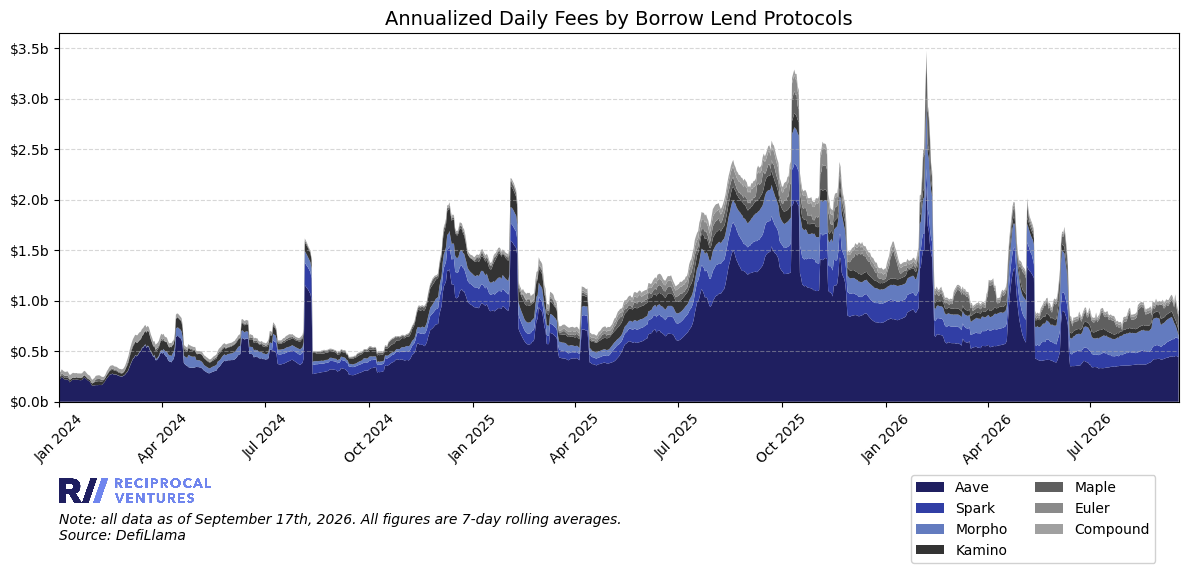

          date          Aave        Morpho      Compound        Kamino  \
986 2026-09-13  4.429620e+08  1.617088e+08  2.876628e+07  5.495445e+07   
987 2026-09-14  4.517926e+08  1.277963e+08  2.749060e+07  5.463174e+07   
988 2026-09-15  4.540596e+08  9.553209e+07  2.748429e+07  5.472664e+07   
989 2026-09-16  4.458139e+08  6.370733e+07  2.857319e+07  5.422070e+07   
990 2026-09-17  4.429588e+08  3.205915e+07  2.963737e+07  5.439308e+07   

            Maple         Euler         Spark  
986  9.785280e+07  2.153912e+07  1.765771e+08  
987  1.994912e+08  2.090199e+07  1.819582e+08  
988  1.558170e+08  2.037174e+07  1.821129e+08  
989  1.316853e+08  2.018961e+07  1.851918e+08  
990  1.354239e+08  2.012610e+07  1.768696e+08  


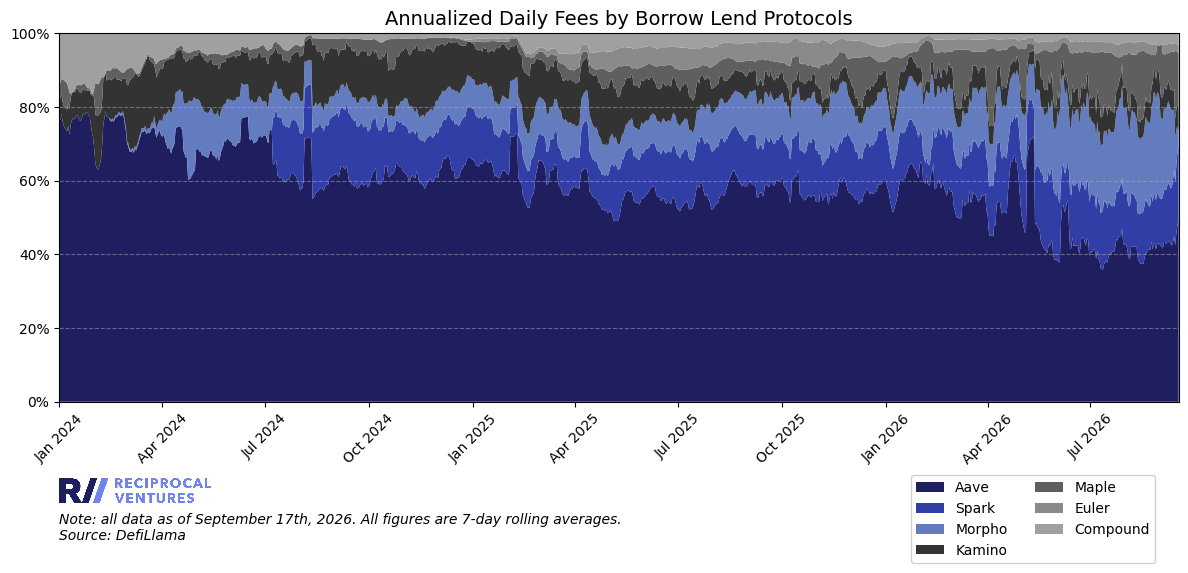

          date          Aave        Morpho      Compound        Kamino  \
986 2026-09-13  4.429620e+08  1.617088e+08  2.876628e+07  5.495445e+07   
987 2026-09-14  4.517926e+08  1.277963e+08  2.749060e+07  5.463174e+07   
988 2026-09-15  4.540596e+08  9.553209e+07  2.748429e+07  5.472664e+07   
989 2026-09-16  4.458139e+08  6.370733e+07  2.857319e+07  5.422070e+07   
990 2026-09-17  4.429588e+08  3.205915e+07  2.963737e+07  5.439308e+07   

            Maple         Euler         Spark  
986  9.785280e+07  2.153912e+07  1.765771e+08  
987  1.994912e+08  2.090199e+07  1.819582e+08  
988  1.558170e+08  2.037174e+07  1.821129e+08  
989  1.316853e+08  2.018961e+07  1.851918e+08  
990  1.354239e+08  2.012610e+07  1.768696e+08  


In [ ]:
METRIC_LABEL = {'dailyFees': 'Fees', 'dailyRevenue': 'Revenue', 'dailyHoldersRevenue': 'Holders Revenue',
                'dailyEarnings': 'Earnings', 'tvl': 'TVL'}
annualize = COHORT_METRIC != 'tvl'
label = ('Annualized Daily ' if annualize else '') + METRIC_LABEL[COHORT_METRIC]

if len(peers) >= 2:
    print(f"Cohort ({category}): {', '.join(peers.values())}")
    for stacked_100 in (False, True):
        visualization.multi_asset_daily_metric([COHORT_METRIC], peers, START_DATE, TRAILING_WINDOW, plots_filepath, date,
                                               chart_title=f'{label} by {pretty_category}',
                                               stacked_100=stacked_100, annualize=annualize, index_from_first_date=False)
else:
    print(f'Fewer than two protocols with {cohort_dir} data in {category}; skipping cohort chart.')


## 4. Category valuation multiples

`protocol_multiples_by_category` plots every category in its input file, so it is given a copy of the processed multiples filtered to the target's category. The filtered copy is derived data (gitignored) and safe to delete.

Outliers: when the processed file is built (`data_processing.process_asset_metrics_data`), each rolling-window multiple (e.g. `FDV-to-annualized-fees-multiple-7d`) more than 100x above or below that protocol's trailing 90-day median for the same multiple is replaced by the prior good value, and the day is listed under `outliers-replaced`. Daily inputs are left alone so lumpy single-day fees survive. This neutralises data breaks (e.g. a DefiLlama fee adapter going dark) without touching the raw pulls.

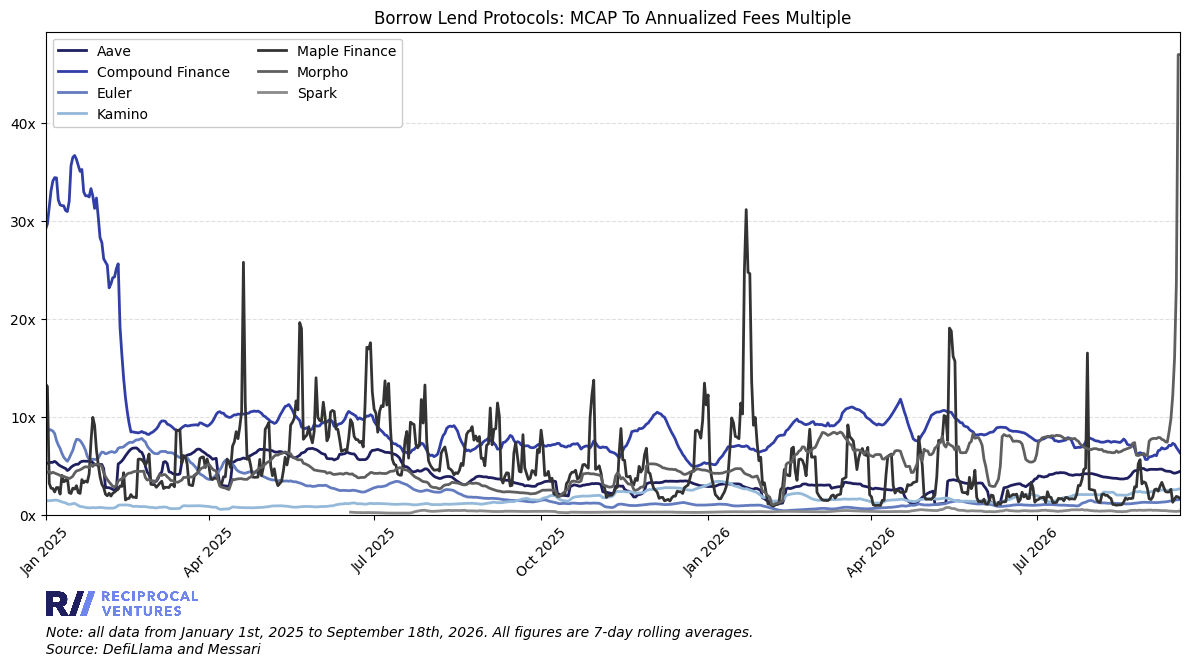

,Aave,Compound Finance,Euler,Kamino,Maple Finance,Morpho,Spark
Median,4x,8x,1x,1x,4x,4x,0x
80th Percentile,5x,10x,4x,2x,8x,7x,0x
20th Percentile,3x,7x,1x,1x,2x,3x,0x
Most Recent,4x,6x,2x,3x,2x,47x,0x


Note: All data from January 1st, 2025 to September 18th, 2026. All figures are 7-day rolling averages.
Source: DefiLlama and Messari.



Table saved to: outputs/tables/borrow_lend_protocols-mcap-to-annualized-fees-multiple-7d-table.png
Done


In [ ]:
if HAS_MULTIPLES:
    filtered_path = data_collection.filter_multiples_to_category(
        category, f'data/processed/valuation-multiples/{slug}-category-only.json')

    visualization.protocol_multiples_by_category(MULTIPLES_METRIC, MULTIPLES_START_DATE, filtered_path,
                                                 plots_filepath, tables_filepath, date)
else:
    print(f"{slug} is not in {data_collection.ALL_PROTOCOLS_MULTIPLES} under '{category}'. "
          f"Add '{category}' to valuation_categories in example-pull-raw-data.ipynb and rerun its valuation cells.")


## 5. Implied valuation from category multiples

The target's latest annualized metric times the category's weighted multiple (median, 20th/80th percentile, most recent), with the target excluded from the category average.

In [ ]:
if HAS_WEIGHTED and HAS_MULTIPLES:
    result = visualization.implied_valuation_from_category_multiples(
        slug,
        name,
        category,
        IMPLIED_VALUATION_MULTIPLE,
        START_DATE,
        TRAILING_WINDOW,
    )

    current = result['protocol_valuation']
    vtype = result['valuation_type']
    rows = []
    for stat, mult in result['category_multiples'].items():
        implied = result['implied_valuations'].get(stat)
        rows.append({
            'Category multiple': helper_functions.format_multiple_value(mult) if mult is not None else 'n/a',
            f'Implied {vtype}': usd(implied),
            'vs. current': f'{implied / current - 1:+.0%}' if implied and current else 'n/a',
        })
    summary = pd.DataFrame(rows, index=list(result['category_multiples'].keys()))

    display(Markdown(
        f"**{name}** current {vtype}: **{usd(current)}** at "
        f"**{helper_functions.format_multiple_value(result['protocol_multiple']) if result.get('protocol_multiple') else 'n/a'}** "
        f"{vtype}/annualized {result['metric'].lower()} "
        f"(annualized {result['metric'].lower()} {usd(result['metric_value'])}, {TRAILING_WINDOW}d trailing, as of {result['metric_date']}). "
        f"Implied {vtype} at {pretty_category} `{result['multiple_type']}`:"
    ))
    display(summary)
    print(f"Category peers used: {', '.join(result['category_protocols'])}")
    print(f"{name} excluded from category multiple: {result['protocol_excluded']}")
    if result.get('latest_outliers_excluded'):
        print(f"Outliers excluded on the latest date (>{result['outlier_factor']}x from category median): "
              f"{', '.join(result['latest_outliers_excluded'])}")

    cm = result['category_multiples']
    if cm.get('Most Recent') and cm.get('Median') and cm['Most Recent'] > 3 * cm['Median']:
        print(f"\nWARNING: 'Most Recent' multiple ({helper_functions.format_multiple_value(cm['Most Recent'])}) is more than 3x the median; "
              f"rely on the median / percentile rows.")
else:
    print('Weighted category multiples unavailable; skipping implied valuation.')


Aave Implied Valuation from Borrow Lend Protocols Multiples

Protocol: Aave
Latest Annualized Fees (7d avg): $443m
Latest FDV (7d avg): $2.2b
Latest FDV/Annualized Fees Multiple (7d avg): 5x
As of: September 17th, 2026

Category: Borrow Lend Protocols
Multiple: FDV Weighted FDV To Annualized Fees Multiple 7D
--------------------------------------------------------------------------------
Statistic            Borrow Lend Protocols Multiple  Implied Valuation
--------------------------------------------------------------------------------
Median                             12x              $5.1b
80th Percentile                    18x              $8.2b
20th Percentile                     7x              $3.3b
Most Recent                        49x             $21.6b
--------------------------------------------------------------------------------

Note: Multiples are 7-day rolling averages and weighted by FDV.
Category multiples from January 1st, 2024 to September 17th, 2026.
Borrow Lend 

**Aave** current FDV: **$2.2b** at **4.6x** FDV/annualized fees (annualized fees $443m, 7d trailing, as of 2026-09-17). Implied FDV at Borrow Lend Protocols `FDV-weighted-FDV-to-annualized-fees-multiple-7d`:

,Category multiple,Implied FDV,vs. current
Median,11.5x,$5.1b,+131%
80th Percentile,18.4x,$8.2b,+271%
20th Percentile,7.5x,$3.3b,+50%
Most Recent,49x,$22b,+882%


Category peers used: Compound Finance, Euler, Kamino, Maple Finance, Morpho, Spark
Aave excluded from category multiple: True



## Files written this run

In [ ]:
written = []
for folder in (plots_filepath, tables_filepath):
    for fn in sorted(os.listdir(folder)):
        p = os.path.join(folder, fn)
        if os.path.getmtime(p) >= run_start:
            written.append(p)
print(f"{len(written)} files written for {name}:")
for p in written:
    print(' ', p)


9 files written for Aave:
  outputs/plots\Aave-7d-combined-metrics.png
  outputs/plots\Aave-7d-fees.png
  outputs/plots\Aave-7d-holders-revenue.png
  outputs/plots\Aave-7d-revenue.png
  outputs/plots\Aave-7d-tvl.png
  outputs/plots\borrow_lend_protocols-mcap-to-annualized-fees-multiple-7d.png
  outputs/plots\multi-asset-7d-fees-100pct-stacked.png
  outputs/plots\multi-asset-7d-fees-stacked.png
  outputs/tables\borrow_lend_protocols-mcap-to-annualized-fees-multiple-7d-table.png
